# UrbanFlow AI — auditable data and forecasting analysis

Run `urbanflow pipeline` first. Every table below reads the real TLC outputs; no synthetic fallback.
The target is observed eligible yellow-taxi pickups, not unserved passenger demand.
All stored timestamps are UTC. NYC calendar features are converted explicitly.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from urbanflow.features import FEATURES, make_features
from urbanflow.modeling import temporal_split
root = Path.cwd()
if not (root / 'data/processed/hourly.parquet').exists():
    root = root.parent
panel = pd.read_parquet(root / 'data/processed/hourly.parquet')
quality = json.loads((root / 'data/processed/quality.json').read_text())
quality

{'engine': 'spark',
 'months': ['2024-01', '2024-02'],
 'quality': [{'month': '2024-01',
   'raw_rows': 2964624,
   'valid_rows': 2952588,
   'rejected_rows': 12036},
  {'month': '2024-02',
   'raw_rows': 3007526,
   'valid_rows': 2996418,
   'rejected_rows': 11108}],
 'panel_rows': 378720,
 'zones': 263,
 'timezone': 'UTC; NYC wall-time source localized before aggregation',
 'sha256': '78fca5f4628de23674bd7f30b384f4b4fdece5a0a2d6b6781bd2c1c210c67b75',
 'source_sha256': {'yellow_tripdata_2024-01.parquet': 'c4d59da7bbc8abaeeeb1727947ee93d9891a71acb42854bd80db1571b2030510',
  'yellow_tripdata_2024-02.parquet': 'c76c43c18c6c6664080dd920baab4928988d5786a6b65980792ca7cd796f9f20'},
 'zero_fraction': 0.6055687579214195}

In [2]:
panel.describe(include='all')

,zone_id,hour,demand
count,378720.000000,378720,378720.000000
mean,132.000000,2024-01-31 04:30:00.000000256,15.708191
min,1.000000,2024-01-01 05:00:00,0.000000
25%,66.000000,2024-01-16 04:45:00,0.000000
50%,132.000000,2024-01-31 04:30:00,0.000000
75%,198.000000,2024-02-15 04:15:00,2.000000
max,263.000000,2024-03-01 04:00:00,846.000000
std,75.921112,NaN,49.746153


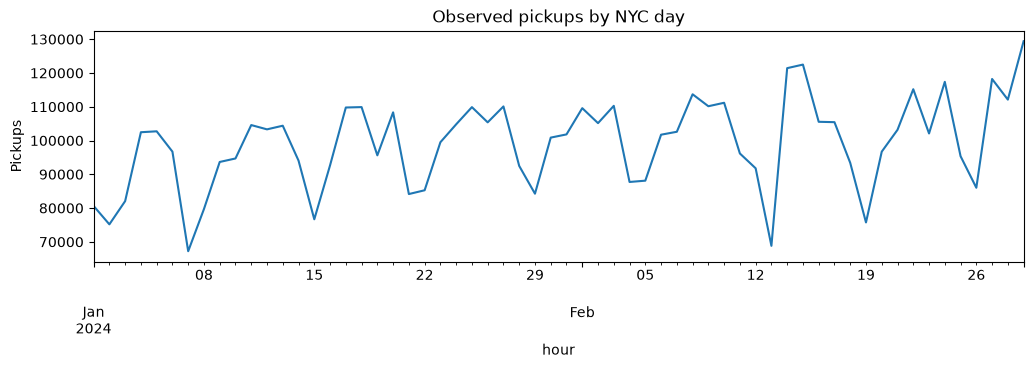

In [3]:
utc = panel.hour.dt.tz_localize('UTC')
local = utc.dt.tz_convert('America/New_York')
daily = panel.groupby(local.dt.tz_localize(None).dt.floor('D')).demand.sum()
daily.plot(figsize=(12, 3), title='Observed pickups by NYC day', ylabel='Pickups');

In [4]:
zones = pd.read_csv(root / 'data/raw/taxi_zone_lookup.csv')
top = panel.groupby('zone_id').demand.sum().nlargest(20).reset_index()
joined = top.merge(zones, left_on='zone_id', right_on='LocationID')
joined[['zone_id','Zone','Borough','demand']]

,zone_id,Zone,Borough,demand
0,161,Midtown Center,Manhattan,290555
1,237,Upper East Side South,Manhattan,283507
2,132,JFK Airport,Queens,272040
3,236,Upper East Side North,Manhattan,270464
4,162,Midtown East,Manhattan,212654
5,230,Times Sq/Theatre District,Manhattan,208603
6,186,Penn Station/Madison Sq West,Manhattan,204937
7,142,Lincoln Square East,Manhattan,201332
8,239,Upper West Side South,Manhattan,179323
9,138,LaGuardia Airport,Queens,176924


## The information boundary

Every lag and rolling window ends before the target hour. The seven-day burn-in is dropped.
Chronological folds contain all zones for each hour; random row splits would leak time.
Test evaluation is rolling one-step: the previous hour's actual count is assumed to have arrived.


In [5]:
features = make_features(panel)
split = temporal_split(features)
pd.DataFrame({name: {'start': getattr(split, name).hour.min(),
                     'end': getattr(split, name).hour.max(),
                     'rows': len(getattr(split, name))}
              for name in ('train', 'validation', 'calibration', 'test')}).T

,start,end,rows
train,2024-01-08 05:00:00,2024-02-09 04:00:00,201984
validation,2024-02-09 05:00:00,2024-02-16 04:00:00,44184
calibration,2024-02-16 05:00:00,2024-02-23 04:00:00,44184
test,2024-02-23 05:00:00,2024-03-01 04:00:00,44184


In [6]:
cutoff = features.hour.max() - pd.Timedelta(hours=24)
changed = panel.copy()
changed.loc[changed.hour >= cutoff, 'demand'] += 10000
changed_features = make_features(changed)
pd.testing.assert_frame_equal(features.loc[features.hour <= cutoff, FEATURES],
                              changed_features.loc[changed_features.hour <= cutoff, FEATURES])
print('Future-label perturbation leaves earlier and target-hour features unchanged.')

C:\Users\Ruben\AppData\Local\Temp\ipykernel_29052\127112441.py:1: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  cutoff = features.hour.max() - pd.Timedelta(hours=24)


Future-label perturbation leaves earlier and target-hour features unchanged.


In [7]:
evaluation_path = root / 'reports/latest/evaluation.json'
evaluation = json.loads(evaluation_path.read_text())
pd.DataFrame(evaluation['validation']).T.sort_values('mae')

,mae,rmse,wape,poisson_deviance
xgboost_deep,3.193270,10.742223,0.195430,1.657151
hist_gradient_boosting,3.236549,11.090684,0.198079,1.682592
xgboost_small,3.305569,11.037395,0.202303,1.760060
seasonal_naive,3.775711,13.221473,0.231076,5.851756


In [8]:
pd.DataFrame(evaluation['cross_validation']).groupby('model').mae.agg(['mean','std'])

,mean,std
model,,
hist_gradient_boosting,2.908693,0.321160
seasonal_naive,3.208030,0.458374
xgboost_deep,2.799744,0.269849
xgboost_small,2.942881,0.228455


In [9]:
results = {'champion': evaluation['test'],
           'weekly_baseline': evaluation['test_baseline']}
pd.DataFrame(results).T

,mae,rmse,wape,poisson_deviance
champion,3.095619,10.704398,0.179843,1.495379
weekly_baseline,3.962656,13.959460,0.230215,6.335337


In [10]:
pd.read_csv(root / 'reports/latest/validation_feature_importance.csv')

,feature,validation_mae_increase,std
0,lag_1,7.946700,0.060731
1,lag_168,7.905422,0.034846
2,mean_168,5.320446,0.050397
3,lag_24,3.893667,0.036315
4,std_24,0.879170,0.010099
5,lag_2,0.299739,0.003069
6,hour_cos,0.243338,0.011753
7,mean_24,0.215327,0.004040
8,hour_sin,0.133414,0.007710
9,dow_sin,0.043106,0.006080


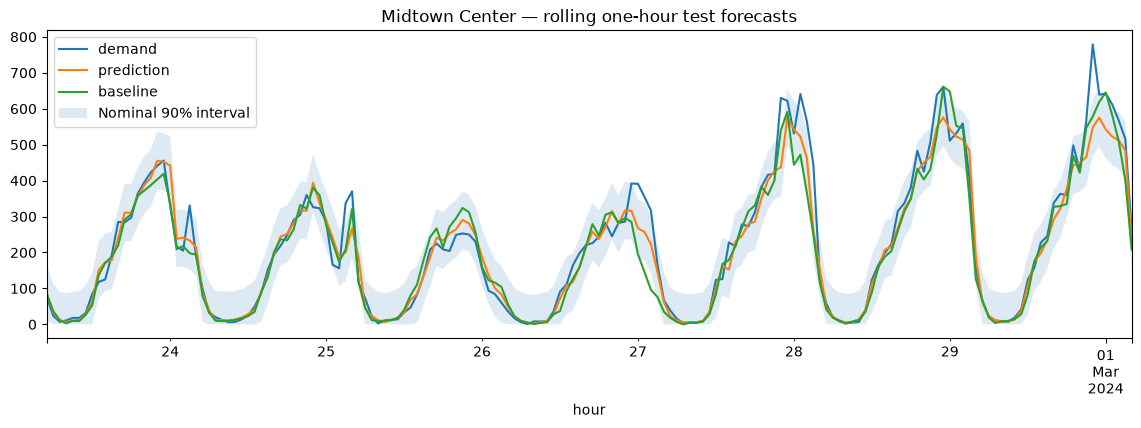

In [11]:
prediction_path = root / 'reports/latest/test_predictions.parquet'
predictions = pd.read_parquet(prediction_path)
zone = predictions[predictions.zone_id.eq(161)].set_index('hour')
ax = zone[['demand', 'prediction', 'baseline']].plot(
    figsize=(14, 4), title='Midtown Center — rolling one-hour test forecasts')
ax.fill_between(zone.index, zone.lower, zone.upper, alpha=0.15, label='Nominal 90% interval')
ax.legend();

In [12]:
per_zone = pd.read_csv(root / 'reports/latest/per_zone.csv')
per_zone.sort_values('actual_total', ascending=False).head(20)

,zone_id,actual_total,coverage,mae,rmse,wape,poisson_deviance,baseline_mae
160,161,36645,0.898810,29.654607,48.073403,0.135952,7.398260,32.803571
236,237,34986,0.875000,23.348603,40.274934,0.112118,6.218874,37.244048
131,132,34426,0.863095,33.938639,44.849340,0.165622,9.948874,37.488095
235,236,33943,0.916667,25.250905,39.559684,0.124979,6.222909,39.904762
161,162,26584,0.892857,21.253135,36.635815,0.134311,5.207499,27.166667
185,186,25176,0.892857,24.506118,35.168213,0.163530,7.347166,31.244048
141,142,25131,0.886905,22.848710,42.299077,0.152743,8.169799,29.357143
229,230,24794,0.928571,21.970793,35.271800,0.148870,5.649931,29.160714
137,138,22962,0.928571,23.582322,34.865801,0.172539,8.678778,30.244048
162,163,22299,0.880952,18.626269,32.130948,0.140330,5.276499,21.785714


In [13]:
{'coverage_90': evaluation['test_coverage_90'],
 'bootstrap': evaluation['bootstrap'],
 'busy_zones': evaluation['test_top20_training_demand_zones']}

{'coverage_90': 0.8827629911280102,
 'bootstrap': {'unit': '24-hour block anchored at test start, all zones kept together',
  'days': 7,
  'iterations': 2000,
  'mae_ci95': [2.808418388140954, 3.462273528806264],
  'paired_mae_gain_ci95': [0.5277041095347068, 1.298291628505461]},
 'busy_zones': {'zones': [161,
   237,
   236,
   132,
   162,
   230,
   186,
   142,
   163,
   239,
   138,
   170,
   234,
   68,
   48,
   141,
   249,
   140,
   79,
   164],
  'model': {'mae': 20.702850516317856,
   'rmse': 34.183346653165664,
   'wape': 0.14462107006941485,
   'poisson_deviance': 5.756322256826364},
  'baseline': {'mae': 26.707440476190477,
   'rmse': 43.828171658790204,
   'wape': 0.18656651254074913,
   'poisson_deviance': 12.23232255968543}}}

## Interpretation and limits

Global MAE includes sparse zones; inspect WAPE and the top-20 cohort chosen using training counts.
Permutation importance is measured on validation with a model fitted only on training.
Correlated lag features dilute individual importances; shuffled rows are an explanatory diagnostic.
Conformal-style residual intervals do not have an exchangeability guarantee for a time series.
Seven test days are a demonstration, not evidence of full-year robustness. More seasons, holiday
backtests, weather forecasts available at issue time, categorical zone encoding, and hourly online
observation ingestion are explicit next steps. TLC monthly release data cannot power live dispatch.
